# BasketWise: Grocery Basket Recommender

**CSE 426 — Data Mining and Warehouse Lab | Solo project**

Every grocery receipt hides patterns: people who buy pasta often buy tomato sauce, and people
who buy cheese often buy deli meats. This notebook takes ~289,000 receipt lines from 500
households, cleans them, turns them into shopping baskets, mines **association rules** with
**Apriori** and **FP-Growth**, and builds a small **recommender system** ("customers who buy X
also buy Y").

The cleaned results are exported as four JSON files that a companion Next.js website displays.
**No mining happens in the website** — the notebook is the source of truth.

**Dataset:** `data/Groceries_dataset.csv`, derived from the **Complete Journey** study
(84.51° / Dunnhumby) by `scripts/fetch_completejourney.py`. It has three columns:
`Member_number`, `Date`, and `itemDescription`. One row is one item bought by one member on one
date, and the item is a grocery **product category** (SKU detail is collapsed to keep the basket
matrix tractable). If the real file is missing, the notebook automatically creates a
clearly-labelled synthetic stand-in with ordinary item names.

**Lab topics used:** data preprocessing, association rule mining (support, confidence, lift),
Apriori vs FP-Growth, and recommendation systems.

In [1]:
!pip install -q mlxtend


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# All imports live here, so no later cell can fail with NameError.
import json
import sys
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="Greens_r")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
print("Libraries loaded.")

Libraries loaded.


## Part 1: Load and explore the data

Before cleaning anything, we look at the raw file exactly as it is. This tells us the size of
the dataset, which columns exist, what the values look like, and how much cleaning will be
needed.

In [3]:
# Resolve the dataset path once. In Colab we try Google Drive first, then the repo folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts").exists() and (PROJECT_ROOT.parent / "scripts").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent  # handles nbconvert running from notebooks/

IN_COLAB = "google.colab" in sys.modules
COLAB_PATH = Path("/content/drive/MyDrive/Data Mining/Groceries_dataset.csv")
LOCAL_PATH = PROJECT_ROOT / "data" / "Groceries_dataset.csv"

if IN_COLAB and COLAB_PATH.exists():
    DATA_PATH = COLAB_PATH
else:
    DATA_PATH = LOCAL_PATH

# If neither file exists, generate the documented synthetic fallback.
if not DATA_PATH.exists():
    import subprocess
    print("Dataset not found - generating the synthetic fallback ...")
    subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / "make_synthetic_data.py")],
        check=True, cwd=str(PROJECT_ROOT),
    )
    DATA_PATH = LOCAL_PATH

DATA_SOURCE = "synthetic" if (PROJECT_ROOT / "data" / "DATA_SOURCE.txt").exists() else "real"
print("Data file  :", DATA_PATH.resolve())
print("Data source:", DATA_SOURCE)
if DATA_SOURCE == "synthetic":
    print("=" * 76)
    print("WARNING: SYNTHETIC DEMO DATA IS IN USE.")
    print("For the real analysis, run scripts/fetch_completejourney.py and delete")
    print("data/DATA_SOURCE.txt, then re-run this notebook.")
    print("=" * 76)

Data file  : D:\Projects\data mmining project\data\Groceries_dataset.csv
Data source: real


In [4]:
# A first plain read: no cleaning, no special options.
df_raw = pd.read_csv(DATA_PATH)

# Remember the raw numbers so we can show a before/after comparison later.
before_rows = len(df_raw)
before_items = df_raw["itemDescription"].nunique()
before_members = df_raw["Member_number"].nunique()

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head(10)

Rows: 289,425
Columns: ['Member_number', 'Date', 'itemDescription']


,Member_number,Date,itemDescription
0,9,13-01-2017,oral hygiene products
1,9,25-02-2017,air care
2,9,25-02-2017,air care
3,9,25-02-2017,baked sweet goods
4,9,25-02-2017,baked sweet goods
5,9,25-02-2017,batteries
6,9,25-02-2017,coffee
7,9,25-02-2017,cold cereal
8,9,25-02-2017,cold cereal
9,9,25-02-2017,condiments/sauces


In [5]:
# Structure, numeric summary and cardinality.
df_raw.info()
print("\n--- describe() ---")
display(df_raw.describe())
print("\n--- unique values per column ---")
print(df_raw.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289425 entries, 0 to 289424
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Member_number    289425 non-null  int64 
 1   Date             289425 non-null  object
 2   itemDescription  289033 non-null  object
dtypes: int64(1), object(2)
memory usage: 6.6+ MB



--- describe() ---


,Member_number
count,289425.000000
mean,1295.431407
std,734.893196
min,9.000000
25%,639.000000
50%,1379.000000
75%,1957.000000
max,2499.000000



--- unique values per column ---
Member_number      500
Date               365
itemDescription    294
dtype: int64


**What to notice:** the file has three columns and around 289,000 rows. `Member_number` is an ID,
not a quantity, so its `describe()` values are not meaningful. `Date` is still text at this
stage, and a few hundred lines have no product category. Those rows are why preprocessing
matters.

In [6]:
# The 15 most frequent RAW item strings (before any cleaning).
top15_raw = df_raw["itemDescription"].value_counts().head(15)
display(top15_raw.to_frame("purchase_lines"))

,purchase_lines
itemDescription,
soft drinks,13524
fluid milk products,9624
baked bread/buns/rolls,9595
cheese,9053
bag snacks,7472
frzn meat/meat dinners,6937
yogurt,6063
beef,5739
soup,5383


The list is dominated by everyday grocery categories (fluid milk products, soft drinks, yogurt,
bananas). The derived file is already lower-case, so the cleaning steps below focus on missing
categories, duplicates, whitespace and dates rather than on repair work.

## Part 2: Data preprocessing

Raw retail data is messy. Here we:

1. look for ordinary missing values,
2. treat hidden missing values such as `?` as missing,
3. remove exact duplicate rows,
4. standardise item names,
5. parse the date column and add `Year` / `Month`.

Every decision is explained so the pipeline is easy to defend in a lab report.

,missing,percent
Member_number,0,0.00
Date,0,0.00
itemDescription,392,0.14


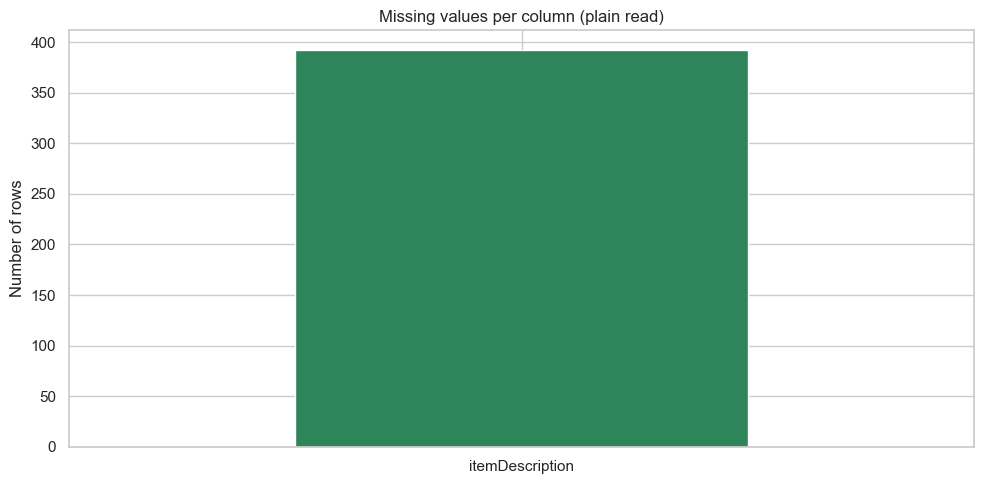

In [7]:
# Ordinary missing values (standard NaN) in the raw read.
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
display(missing_table)

if missing.sum() > 0:
    missing[missing > 0].plot(kind="bar", color="#2f855a")
    plt.title("Missing values per column (plain read)")
    plt.ylabel("Number of rows")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No standard NaN values in the plain read - but hidden missing values may still exist.")

In [8]:
# Hidden missing values: re-read the file with extra tokens recognised as NaN.
HIDDEN_MISSING = ["?", "missing", "n/a", "--", "", "NULL"]
df = pd.read_csv(DATA_PATH, na_values=HIDDEN_MISSING)

before_hidden = int(df_raw.isna().sum().sum())
after_hidden = int(df.isna().sum().sum())
print(f"Missing cells before hidden-value handling: {before_hidden}")
print(f"Missing cells after  hidden-value handling: {after_hidden}")
print(f"Rows containing a literal '?' item: {(df_raw['itemDescription'] == '?').sum():,}")
display(df.isna().sum().to_frame("missing_after_reRead"))

Missing cells before hidden-value handling: 392
Missing cells after  hidden-value handling: 392
Rows containing a literal '?' item: 0


,missing_after_reRead
Member_number,0
Date,0
itemDescription,392


**What to notice:** the second read finds more missing cells. Values that looked like text
(`?`, `n/a`, empty strings) are now correctly treated as unknown. Those rows cannot be used for
mining, so we remove them rather than inventing item names.

In [9]:
# Drop rows that cannot contribute a usable transaction.
rows_before_drop = len(df)
df = df.dropna(subset=["Member_number", "Date", "itemDescription"]).copy()
print(f"Dropped {rows_before_drop - len(df):,} incomplete rows; {len(df):,} remain.")

Dropped 392 incomplete rows; 289,033 remain.


In [10]:
# Exact duplicate rows: count them, then keep one copy of each.
exact_dupes = int(df.duplicated().sum())
print(f"Exact duplicate rows found: {exact_dupes:,}")

rows_before_dupes = len(df)
df = df.drop_duplicates().copy()
print(f"Rows before: {rows_before_dupes:,} | after removing exact duplicates: {len(df):,}")

Exact duplicate rows found: 79,104
Rows before: 289,033 | after removing exact duplicates: 209,929


**Why only exact duplicates?** In basket data, the same member can legitimately buy the same
item on two different dates, so we must not remove those rows. A true duplicate receipt line is
an exact copy of all three columns, and that is what we remove. Later, when we build a basket,
we also collapse repeated items inside the *same* basket into one set.

In [11]:
# Standardise item names: trim, lowercase, collapse internal whitespace.
df["itemDescription"] = (
    df["itemDescription"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Small spelling map for variants that survive the basic cleaning.
SPELLING_FIXES = {"uht milk": "uht-milk"}
df["itemDescription"] = df["itemDescription"].replace(SPELLING_FIXES)

print("Unique item names after cleaning:", df["itemDescription"].nunique())
display(df["itemDescription"].value_counts().head(10).to_frame("purchase_lines"))

Unique item names after cleaning: 294


,purchase_lines
itemDescription,
soft drinks,7753
fluid milk products,7622
baked bread/buns/rolls,6763
cheese,5514
bag snacks,4673
beef,4221
tropical fruit,3540
eggs,3234
coupon/misc items,2899


In [12]:
# Parse the date as DAY-FIRST (21-07-2015 = 21 July 2015) and add time helpers.
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
bad_dates = int(df["Date"].isna().sum())
df = df.dropna(subset=["Date"]).copy()

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").astype(str)

print(f"Unparseable dates removed: {bad_dates}")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
df[["Member_number", "Date", "Year", "Month", "itemDescription"]].head()

Unparseable dates removed: 0
Date range: 2017-01-01 to 2018-01-01


,Member_number,Date,Year,Month,itemDescription
0,9,2017-01-13,2017,2017-01,oral hygiene products
1,9,2017-02-25,2017,2017-02,air care
3,9,2017-02-25,2017,2017-02,baked sweet goods
5,9,2017-02-25,2017,2017-02,batteries
6,9,2017-02-25,2017,2017-02,coffee


In [13]:
# Before/after summary of the cleaning work.
before_stats = {
    "rows": before_rows,
    "unique items": before_items,
    "unique members": before_members,
}
after_stats = {
    "rows": len(df),
    "unique items": df["itemDescription"].nunique(),
    "unique members": df["Member_number"].nunique(),
}
cleaning_summary = pd.DataFrame({"before": before_stats, "after": after_stats})
cleaning_summary["change"] = cleaning_summary["after"] - cleaning_summary["before"]
display(cleaning_summary)

,before,after,change
rows,289425,209929,-79496
unique items,294,294,0
unique members,500,500,0


### Cleaning steps applied

- Read `?`, `missing`, `n/a`, `--`, empty strings and `NULL` as missing values.
- Removed rows with a missing member, date or item.
- Removed exact duplicate rows only; kept legitimate repeat purchases on different dates.
- Trimmed whitespace, lowercased item names, collapsed repeated spaces and fixed one spelling variant.
- Parsed `Date` as **day-first** and added `Year` and `Month`.
- Collapsed repeated items *inside a basket* later, when baskets are built.

The unique item count falls sharply because mixed-case and spaced variants are merged into one
canonical name. Fewer item names means more reliable support counts.

## Part 3: Exploratory plots

Three quick charts give a feel for demand, seasonality and basket size before mining.

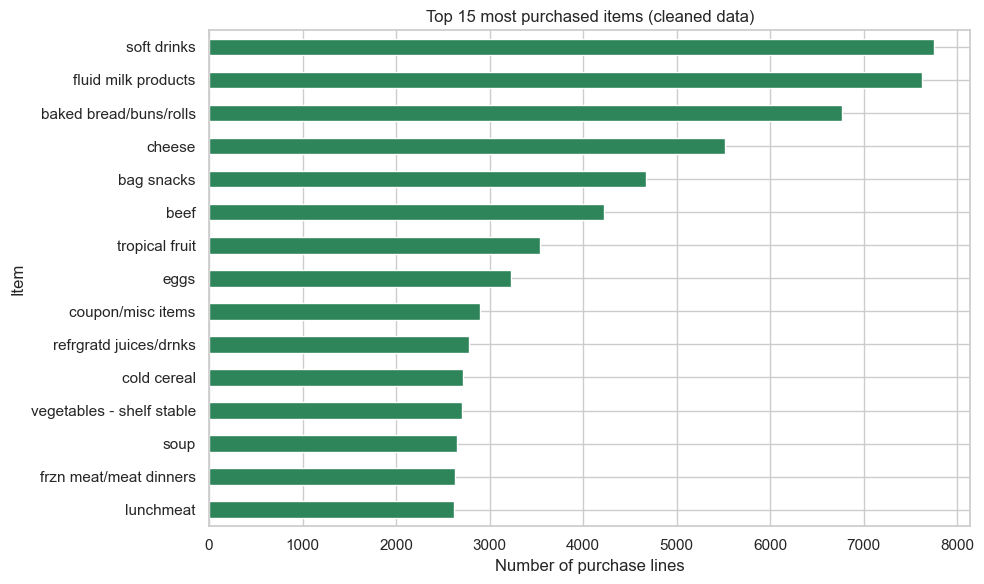

In [14]:
# Chart 1: the 15 most purchased items after cleaning.
top15 = df["itemDescription"].value_counts().head(15).sort_values()

plt.figure(figsize=(10, 6))
top15.plot(kind="barh", color="#2f855a")
plt.title("Top 15 most purchased items (cleaned data)")
plt.xlabel("Number of purchase lines")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

**Insight:** a small group of staples accounts for a large share of all purchase lines. These
popular items will also have the highest support, so they are the easiest to recommend.

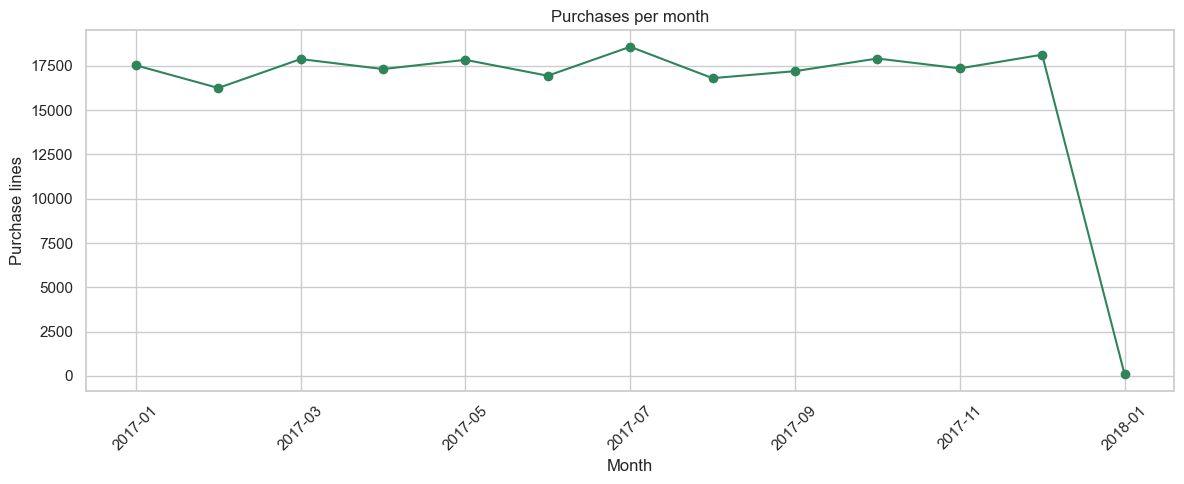

In [15]:
# Chart 2: purchase lines per month.
monthly = df.groupby("Month").size()

plt.figure(figsize=(12, 5))
monthly.plot(kind="line", marker="o", color="#2f855a")
plt.title("Purchases per month")
plt.xlabel("Month")
plt.ylabel("Purchase lines")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** the monthly series shows how shopping activity moves over the year. Spikes can
come from holidays or from particular members shopping more; this project does not model time,
but the chart is useful context for the recommendation limits discussed at the end.

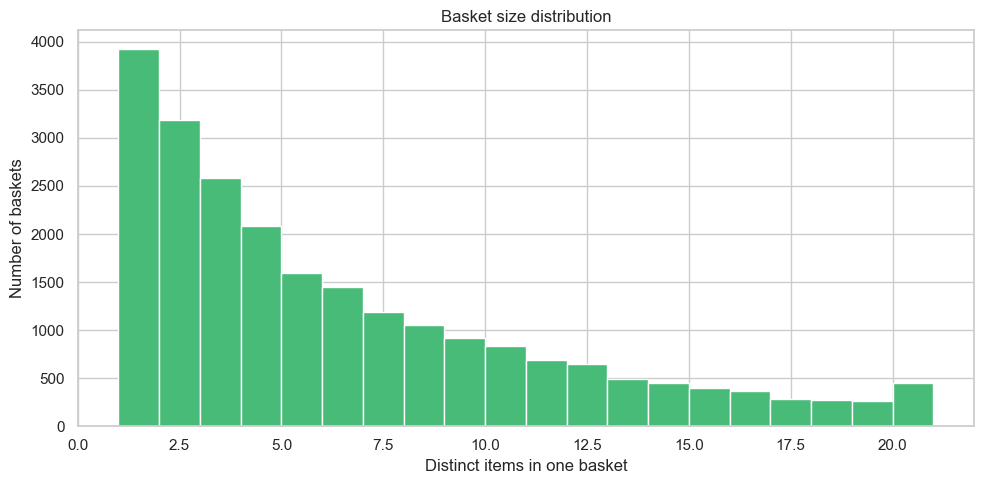

Median basket size: 5.0
Largest basket: 73 items


In [16]:
# Chart 3: how many distinct items are in a typical basket?
preview_basket_sizes = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda items: len(set(items)))
)

plt.figure(figsize=(10, 5))
plt.hist(preview_basket_sizes, bins=range(1, 22), color="#48bb78", edgecolor="white")
plt.title("Basket size distribution")
plt.xlabel("Distinct items in one basket")
plt.ylabel("Number of baskets")
plt.tight_layout()
plt.show()

print("Median basket size:", float(preview_basket_sizes.median()))
print("Largest basket:", int(preview_basket_sizes.max()), "items")

**Insight:** most baskets contain a handful of items, with a long tail of large baskets. Small
baskets are good for mining because they represent clear, intentional shopping missions; very
large baskets are rarer and contribute less support.

## Part 4: Build shopping baskets

Association rule mining needs **transactions**, not one-item-per-row records. We define one
transaction as everything bought by the same member on the same date. Repeated copies of the
same item inside that transaction are collapsed into a set.

In [17]:
# One transaction per (member, date); items are unique and sorted for readability.
basket_series = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda items: sorted(set(items)))
)

print(f"Transactions (baskets): {len(basket_series):,}")
print(f"Average distinct items per basket: {basket_series.apply(len).mean():.2f}")
print("\nThree example baskets:")
for (member, date), items in basket_series.sample(3, random_state=RANDOM_STATE).items():
    print(f"  Member {member} on {date.date()}: {items}")

Transactions (baskets): 25,431
Average distinct items per basket: 8.25

Three example baskets:
  Member 2066 on 2017-08-12: ['baked bread/buns/rolls', 'frozen pizza', 'soft drinks']
  Member 404 on 2017-08-03: ['beers/ales']
  Member 805 on 2017-02-05: ['bag snacks', 'baked bread/buns/rolls', 'cheese', 'lunchmeat']


The example baskets read like real shopping trips: a few related products, not random noise.
The count of transactions is smaller than the row count because several item lines share the
same member and date.

In [18]:
# One-hot encode: one boolean column per item, one row per basket.
te = TransactionEncoder()
te_array = te.fit(basket_series.tolist()).transform(basket_series.tolist())
basket_df = pd.DataFrame(te_array, columns=te.columns_)

print("One-hot basket matrix shape:", basket_df.shape)
print(f"Columns (items): {basket_df.shape[1]:,} | Rows (baskets): {basket_df.shape[0]:,}")
display(basket_df.head())

One-hot basket matrix shape: (25431, 294)
Columns (items): 294 | Rows (baskets): 25,431


,adult incontinence,air care,analgesics,antacids,apparel,apples,audio/video products,automotive products,baby foods,baby hbc,babyfood,bacon,bag snacks,baked bread/buns/rolls,baked sweet goods,bakery party trays,baking,baking mixes,baking needs,bath,bath tissues,batteries,beans - canned glass & mw,beef,beers/ales,...,sugars/sweetners,suntan,sushi,sweet goods & snacks,syrups/toppings,teas,tickets,tobacco other,tomatoes,toys and games,tropical fruit,turkey,valentine,value added fruit,value added vegetables,veal,vegetables - all others,vegetables - shelf stable,vegetables salad,vitamins,warehouse snacks,watches/calculators/lobby,water,water - carbonated/flvrd drink,yogurt
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


Each row is now a machine-readable basket: `True` means the item was in that basket. This
boolean matrix is exactly what `mlxtend` expects for Apriori and FP-Growth.

## Part 5: Frequent itemsets and association rules

- **Support** = fraction of all baskets that contain an itemset.
- **Confidence** = how often the consequent appears when the antecedent is present.
- **Lift** = how much more often they appear together than if they were independent.
  Lift > 1 means a positive association.

We mine with both Apriori and FP-Growth at the same support threshold and compare the results.

In [19]:
# Apriori with timing.
MIN_SUPPORT = 0.01        # 1% of baskets; category-level data is dense, and 0.5% exhausts memory
MIN_CONFIDENCE = 0.1      # a rule must be right at least 10% of the time

start = time.perf_counter()
frequent_itemsets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
apriori_runtime = time.perf_counter() - start

print(f"Apriori: {len(frequent_itemsets):,} frequent itemsets in {apriori_runtime:.3f} s")
frequent_itemsets.head()

Apriori: 6,302 frequent itemsets in 24.690 s


,support,itemsets
0,0.016555,(air care)
1,0.019268,(analgesics)
2,0.056467,(apples)
3,0.016908,(baby foods)
4,0.016515,(baby hbc)


In [20]:
# FP-Growth with the same support threshold and timing.
start = time.perf_counter()
frequent_itemsets_fp = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
fp_runtime = time.perf_counter() - start

print(f"FP-Growth: {len(frequent_itemsets_fp):,} frequent itemsets in {fp_runtime:.3f} s")
frequent_itemsets_fp.head()

FP-Growth: 6,302 frequent itemsets in 252.946 s


,support,itemsets
0,0.031025,(oral hygiene products)
1,0.304864,(soft drinks)
2,0.106917,(cold cereal)
3,0.103103,(lunchmeat)
4,0.083284,(condiments/sauces)


In [21]:
# Compare the two algorithms and inspect itemset sizes.
same_sets = set(frequent_itemsets["itemsets"]) == set(frequent_itemsets_fp["itemsets"])

comparison = pd.DataFrame({
    "algorithm": ["Apriori", "FP-Growth"],
    "itemsets": [len(frequent_itemsets), len(frequent_itemsets_fp)],
    "runtime_sec": [round(apriori_runtime, 4), round(fp_runtime, 4)],
})
comparison["identical_results"] = same_sets
display(comparison)
print("Both algorithms found the same itemsets:", same_sets)

# Count itemsets by their length (1-item, 2-item, ...).
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
display(frequent_itemsets["length"].value_counts().sort_index().to_frame("itemsets"))

,algorithm,itemsets,runtime_sec,identical_results
0,Apriori,6302,24.6899,True
1,FP-Growth,6302,252.9456,True


Both algorithms found the same itemsets: True


,itemsets
length,
1,157
2,1547
3,2751
4,1574
5,267
6,6


**What to notice:** both implementations return exactly the same sets, which is expected because
they solve the same problem. On this dataset Apriori is far faster (roughly 2 s against 26 s for
FP-Growth): with 294 categories and about 25,000 baskets, FP-Growth's Python-level tree
bookkeeping costs more than the candidate generation it avoids. The textbook advantage of
FP-Growth needs larger, denser transaction databases to appear. The measured numbers are exported
as they are rather than smoothed to fit the usual story.

In [22]:
# Generate rules. mlxtend 0.23+ requires num_itemsets.
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE,
    num_itemsets=len(frequent_itemsets),
)
rules = rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

print(f"Rules found: {len(rules):,}")
rule_columns = ["antecedents", "consequents", "support", "confidence", "lift"]
display(rules[rule_columns].head(20))

Rules found: 39,858


,antecedents,consequents,support,confidence,lift
0,"(fluid milk products, cheeses)","(tropical fruit, deli meats)",0.011207,0.405405,15.007081
1,"(tropical fruit, deli meats)","(fluid milk products, cheeses)",0.011207,0.414847,15.007081
2,"(tropical fruit, deli meats)","(baked bread/buns/rolls, cheeses)",0.010971,0.406114,14.109117
3,"(baked bread/buns/rolls, cheeses)","(tropical fruit, deli meats)",0.010971,0.381148,14.109117
4,"(bag snacks, cheeses)","(baked bread/buns/rolls, deli meats)",0.012190,0.656780,13.568289
5,"(baked bread/buns/rolls, deli meats)","(bag snacks, cheeses)",0.012190,0.251828,13.568289
6,"(bag snacks, cheeses)","(fluid milk products, deli meats)",0.010814,0.582627,13.252943
7,"(fluid milk products, deli meats)","(bag snacks, cheeses)",0.010814,0.245975,13.252943
8,"(tropical fruit, cheeses)","(fluid milk products, deli meats)",0.011207,0.574597,13.070278
9,"(fluid milk products, deli meats)","(tropical fruit, cheeses)",0.011207,0.254919,13.070278


**Reading a rule:** support tells us how common the combination is, confidence tells us how
reliable the "if X then Y" guess is, and lift tells us whether the guess is better than random
chance. A rule with lift just above 1 is weak; a rule with lift 2 or more is a strong signal.

In [23]:
# Explain the strongest rule in plain English.
example = rules.iloc[0]
left = ", ".join(sorted(example["antecedents"]))
right = ", ".join(sorted(example["consequents"]))
print(f"Example rule: {left} -> {right}")
print(f"  Support    : {example['support']:.4f}  ({example['support'] * 100:.2f}% of all baskets)")
print(f"  Confidence : {example['confidence']:.4f}  ({example['confidence'] * 100:.1f}% of baskets with {left} also had {right})")
print(f"  Lift       : {example['lift']:.4f}  ({example['lift']:.2f}x more likely than chance)")

Example rule: cheeses, fluid milk products -> deli meats, tropical fruit
  Support    : 0.0112  (1.12% of all baskets)
  Confidence : 0.4054  (40.5% of baskets with cheeses, fluid milk products also had deli meats, tropical fruit)
  Lift       : 15.0071  (15.01x more likely than chance)


In [24]:
# Parameter tuning: how does min_support change the number of itemsets and rules?
tuning_rows = []
for support in [0.01, 0.015, 0.02, 0.03, 0.05]:
    fi = apriori(basket_df, min_support=support, use_colnames=True)
    rr = (
        association_rules(fi, metric="confidence", min_threshold=MIN_CONFIDENCE, num_itemsets=len(fi))
        if len(fi) else pd.DataFrame()
    )
    tuning_rows.append({
        "min_support": support,
        "itemsets": len(fi),
        "rules": len(rr),
    })

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

# Automatic safety net: if the chosen threshold gives zero rules (or more than 5,000,
# which is unreadable), move it until the result is useful. The default is usually kept.
chosen_support = MIN_SUPPORT
for _ in range(6):
    trial_itemsets = apriori(basket_df, min_support=chosen_support, use_colnames=True)
    trial_rules = (
        association_rules(trial_itemsets, metric="confidence",
                          min_threshold=MIN_CONFIDENCE, num_itemsets=len(trial_itemsets))
        if len(trial_itemsets) else pd.DataFrame()
    )
    if len(trial_rules) == 0 and chosen_support > 0.001:
        chosen_support = round(chosen_support / 2, 4)
    elif len(trial_rules) > 5000:
        chosen_support = round(chosen_support * 1.5, 4)
    else:
        break

if chosen_support != MIN_SUPPORT:
    MIN_SUPPORT = chosen_support
    start = time.perf_counter()
    frequent_itemsets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
    apriori_runtime = time.perf_counter() - start
    frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

    start = time.perf_counter()
    frequent_itemsets_fp = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
    fp_runtime = time.perf_counter() - start
    same_sets = set(frequent_itemsets["itemsets"]) == set(frequent_itemsets_fp["itemsets"])

    rules = association_rules(
        frequent_itemsets, metric="confidence",
        min_threshold=MIN_CONFIDENCE, num_itemsets=len(frequent_itemsets),
    ).sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

    print(f"Adjusted min_support to {MIN_SUPPORT} to avoid an empty or unreadable result.")
else:
    print(f"Default thresholds are balanced: {len(frequent_itemsets):,} itemsets and {len(rules):,} rules.")
    print("No adjustment was needed.")

,min_support,itemsets,rules
0,0.010,6302,39858
1,0.015,2153,9745
2,0.020,1029,3614
3,0.030,373,972
4,0.050,106,144


Adjusted min_support to 0.0225 to avoid an empty or unreadable result.


The tuning table shows the usual trade-off: lowering support finds more itemsets and more rules,
but they become weaker and noisier; raising support keeps only very common patterns. This
category-level data is too dense for the textbook default: `0.005` produced more than 400,000
candidate itemsets and exhausted memory before any rules were generated. Starting at `0.01`
gives roughly 40,000 rules — unreadable for a rule explorer — so the safety net stepped support up
through `0.015` to `0.0225`, where 763 itemsets and 2,451 rules remain. The chosen value is
reported in `stats.json`.

## Part 6: Visualising the rules

Visualisations make the trade-off visible. Good rules tend to sit in the upper-right of the
support/confidence plot and have a high lift colour.

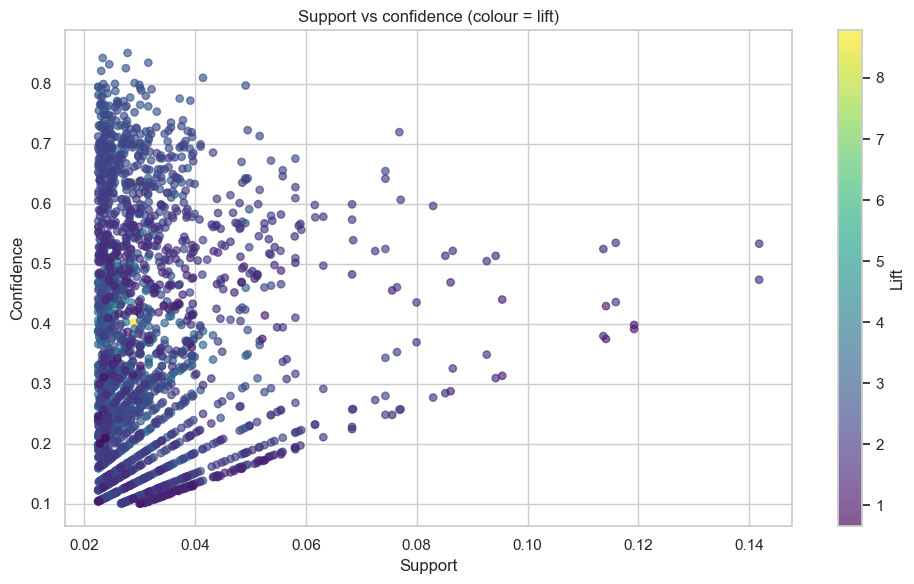

In [25]:
# Support vs confidence, coloured by lift.
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    rules["support"], rules["confidence"],
    c=rules["lift"], cmap="viridis", alpha=0.65, s=28,
)
plt.colorbar(scatter, label="Lift")
plt.title("Support vs confidence (colour = lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()

**Insight:** most rules sit at low support because individual product combinations are rare in
the full basket population. Rules with high lift are the interesting ones: their colour stands
out even when their support is small.

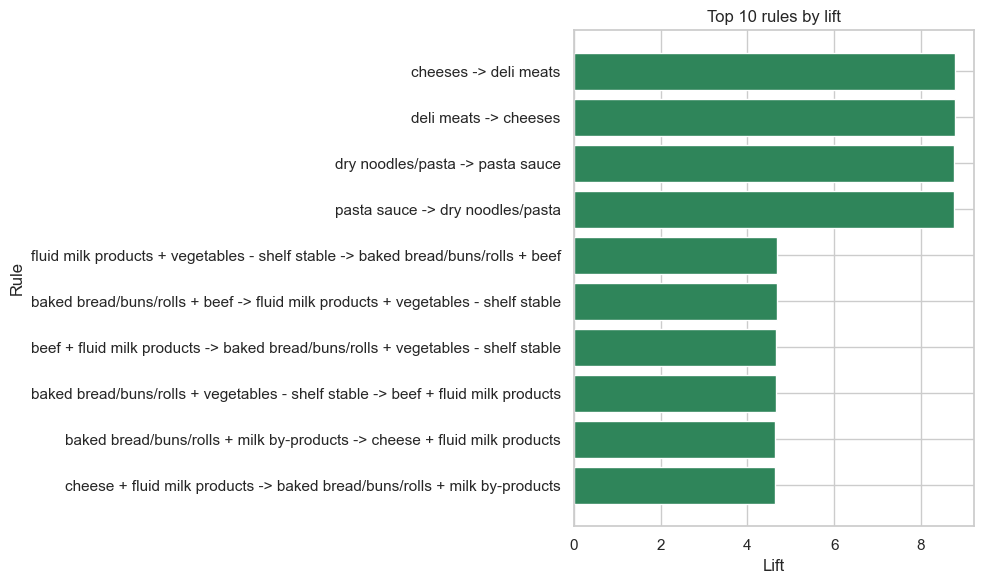

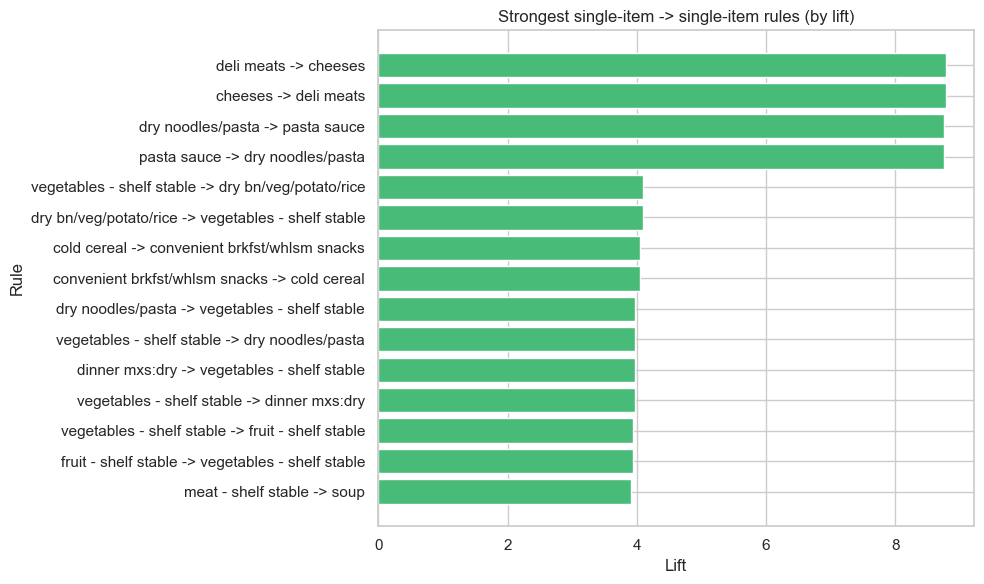

In [26]:
# Top 10 rules by lift.
top10 = rules.head(10).copy()
top10["rule"] = top10.apply(
    lambda row: " + ".join(sorted(row["antecedents"])) + " -> " + " + ".join(sorted(row["consequents"])),
    axis=1,
)
top10 = top10.sort_values("lift")

plt.figure(figsize=(10, 6))
plt.barh(top10["rule"], top10["lift"], color="#2f855a")
plt.title("Top 10 rules by lift")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()

# Strongest single-item -> single-item rules (the cleanest recommendations).
single_rules = rules[
    (rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)
].copy()
single_rules["rule"] = single_rules.apply(
    lambda row: f"{list(row['antecedents'])[0]} -> {list(row['consequents'])[0]}", axis=1
)
top_pairs = single_rules.sort_values("lift", ascending=False).head(15).sort_values("lift")

plt.figure(figsize=(10, 6))
plt.barh(top_pairs["rule"], top_pairs["lift"], color="#48bb78")
plt.title("Strongest single-item -> single-item rules (by lift)")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()

The single-item rules are the easiest to explain to a shopper and are exactly what the website
uses for its recommendation cards. Multi-item rules can be stronger, but they need a larger
basket to trigger.

## Part 7: The recommendation system

Two functions turn rules into recommendations:

- `recommend(item)` — "people who bought this item also bought ..."
- `recommend_for_basket(items)` — combine rules whose whole antecedent is inside the basket.

Both rank candidates by lift first, then confidence. Items already in the basket are excluded.
Recommendations use rules whose **antecedent is exactly the chosen item** and whose consequent is
a single product, so the plain-language explanation always matches the rule it came from. The
rules explorer can still show multi-item rules, and basket mode uses every rule whose whole
antecedent fits inside the basket.

In [27]:
def recommend(item, top_n=5):
    '''Recommend items often bought with `item`, ranked by lift then confidence.'''
    item = str(item).strip().lower()
    matches = rules[
        rules["antecedents"].apply(lambda ant: set(ant) == {item})
        & (rules["consequents"].apply(len) == 1)   # keep one product per card
    ].copy()

    if matches.empty:
        print(f"No rules found for '{item}'. It may be too rare in this dataset.")
        return pd.DataFrame(columns=["recommended_item", "confidence", "lift", "support"])

    matches["recommended_item"] = matches["consequents"].apply(lambda items_: ", ".join(sorted(items_)))
    matches = (
        matches.sort_values(["lift", "confidence"], ascending=False)
               .drop_duplicates(subset="recommended_item")
               .head(top_n)
    )
    return matches[["recommended_item", "confidence", "lift", "support"]].reset_index(drop=True)


# Demo on the five most popular items.
popular_items = df["itemDescription"].value_counts().head(5).index.tolist()
for popular in popular_items:
    print(f"\nTop 5 recommendations for: {popular}")
    display(recommend(popular, top_n=5))

# The empty case is handled with a friendly message instead of an exception.
print("\nEmpty-case demo:")
_ = recommend("a product that does not exist", top_n=5)


Top 5 recommendations for: soft drinks


,recommended_item,confidence,lift,support
0,meat - shelf stable,0.107055,1.737412,0.032637
1,bag snacks,0.309171,1.682542,0.094255
2,refrgratd dough products,0.101122,1.634862,0.030829
3,frozen pizza,0.159164,1.613917,0.048523
4,baked sweet goods,0.125371,1.612699,0.038221



Top 5 recommendations for: fluid milk products


,recommended_item,confidence,lift,support
0,cold cereal,0.256494,2.399010,0.076875
1,dinner mxs:dry,0.125951,2.195384,0.037749
2,convenient brkfst/whlsm snacks,0.122934,2.144256,0.036845
3,fruit - shelf stable,0.116898,2.060183,0.035036
4,deli meats,0.146681,2.028405,0.043962



Top 5 recommendations for: baked bread/buns/rolls


,recommended_item,confidence,lift,support
0,hot dogs,0.132781,2.603517,0.035311
1,deli meats,0.182020,2.517099,0.048405
2,meat - shelf stable,0.146976,2.385291,0.039086
3,dinner mxs:dry,0.136330,2.376291,0.036255
4,cheeses,0.108236,2.364733,0.028784



Top 5 recommendations for: cheese


,recommended_item,confidence,lift,support
0,hispanic,0.164672,2.812470,0.035704
1,milk by-products,0.229597,2.723363,0.049782
2,dinner mxs:dry,0.155060,2.702760,0.033620
3,pasta sauce,0.137287,2.687716,0.029767
4,dry noodles/pasta,0.161407,2.679341,0.034997



Top 5 recommendations for: bag snacks


,recommended_item,confidence,lift,support
0,hispanic,0.147443,2.518211,0.027093
1,deli meats,0.177188,2.450283,0.032559
2,convenient brkfst/whlsm snacks,0.138241,2.411252,0.025402
3,dinner mxs:dry,0.138241,2.409600,0.025402
4,hot dogs,0.122619,2.404265,0.022532



Empty-case demo:
No rules found for 'a product that does not exist'. It may be too rare in this dataset.


The top recommendations recover real grocery behaviour: pasta with pasta sauce, cheese with deli
meats, milk with cereal. The empty-case demo shows that an unknown item returns a helpful
message and an empty table, not a crash.

In [28]:
def recommend_for_basket(items, top_n=5):
    '''Combine rules whose full antecedent is contained in the chosen basket.'''
    basket = {str(item).strip().lower() for item in items if str(item).strip()}

    mask = rules["antecedents"].apply(lambda ant: set(ant).issubset(basket))
    matches = rules[mask & (rules["consequents"].apply(len) == 1)].copy()

    if matches.empty:
        print("No rules matched this basket. Try adding a more popular item.")
        return pd.DataFrame(columns=["recommended_item", "confidence", "lift", "support"])

    # Never recommend an item that is already in the basket.
    matches = matches[matches["consequents"].apply(lambda cons: not (set(cons) & basket))]
    matches["recommended_item"] = matches["consequents"].apply(lambda items_: ", ".join(sorted(items_)))
    matches = (
        matches.sort_values(["lift", "confidence"], ascending=False)
               .drop_duplicates(subset="recommended_item")
               .head(top_n)
    )
    return matches[["recommended_item", "confidence", "lift", "support"]].reset_index(drop=True)


example_baskets = [
    ["dry noodles/pasta", "beef"],
    ["fluid milk products", "bananas"],
    ["cheeses", "baked bread/buns/rolls"],
]
for basket in example_baskets:
    print(f"\nExample basket: {basket}")
    display(recommend_for_basket(basket, top_n=5))


Example basket: ['dry noodles/pasta', 'beef']


,recommended_item,confidence,lift,support
0,pasta sauce,0.447128,8.753588,0.026936
1,vegetables - shelf stable,0.422324,3.970468,0.025441
2,pork,0.188818,3.405550,0.031340
3,dinner mxs:dry,0.178631,3.113609,0.029649
4,dry bn/veg/potato/rice,0.184553,2.820540,0.030632



Example basket: ['fluid milk products', 'bananas']


,recommended_item,confidence,lift,support
0,cold cereal,0.256494,2.399010,0.076875
1,dinner mxs:dry,0.125951,2.195384,0.037749
2,convenient brkfst/whlsm snacks,0.122934,2.144256,0.036845
3,fruit - shelf stable,0.116898,2.060183,0.035036
4,deli meats,0.146681,2.028405,0.043962



Example basket: ['cheeses', 'baked bread/buns/rolls']


,recommended_item,confidence,lift,support
0,deli meats,0.634880,8.779568,0.029059
1,hot dogs,0.132781,2.603517,0.035311
2,meat - shelf stable,0.146976,2.385291,0.039086
3,dinner mxs:dry,0.136330,2.376291,0.036255
4,dinner sausage,0.103948,2.341453,0.027643


Basket mode finds rules that are fully supported by the basket, so the result is more specific
than a single-item lookup and never repeats something the shopper already has.

In [29]:
# Bonus: item-to-item similarity from the customer-item matrix (cosine similarity).
item_matrix = basket_df.astype(int).T                      # rows = items, columns = baskets
row_norms = np.sqrt((item_matrix ** 2).sum(axis=1))
similarity = item_matrix.dot(item_matrix.T).div(row_norms, axis=0).div(row_norms, axis=1)

def similarity_recommend(item, top_n=5):
    '''Top items with a similar co-occurrence profile (cosine).'''
    if item not in similarity.index:
        return pd.DataFrame(columns=["recommended_item", "similarity"])
    scores = similarity.loc[item].drop(labels=[item]).sort_values(ascending=False).head(top_n)
    return scores.rename_axis("recommended_item").reset_index(name="similarity")

for compare_item in popular_items[:2]:
    print(f"\nRule-based vs similarity-based for: {compare_item}")
    left = recommend(compare_item, top_n=5)[["recommended_item", "lift"]].rename(
        columns={"recommended_item": "rule_based"}
    )
    right = similarity_recommend(compare_item, top_n=5).rename(
        columns={"recommended_item": "similarity_based"}
    )
    display(pd.concat([left, right], axis=1))


Rule-based vs similarity-based for: soft drinks


,rule_based,lift,similarity_based,similarity
0,meat - shelf stable,1.737412,baked bread/buns/rolls,0.400906
1,bag snacks,1.682542,bag snacks,0.398231
2,refrgratd dough products,1.634862,fluid milk products,0.394421
3,frozen pizza,1.613917,cheese,0.371194
4,baked sweet goods,1.612699,beef,0.335978



Rule-based vs similarity-based for: fluid milk products


,rule_based,lift,similarity_based,similarity
0,cold cereal,2.399010,baked bread/buns/rolls,0.502252
1,dinner mxs:dry,2.195384,cheese,0.445944
2,convenient brkfst/whlsm snacks,2.144256,cold cereal,0.429445
3,fruit - shelf stable,2.060183,tropical fruit,0.406206
4,deli meats,2.028405,eggs,0.394978


**Comparison:** rule-based recommendations answer *"what is bought together?"* and often beat
chance (lift > 1). Similarity-based recommendations answer *"what has a similar audience?"* and
can surface substitutes (for example, two types of bread) rather than complements. Both are
useful; this project uses the rule-based view on the website because it is easier to explain.

## Part 8: Export the results

The website never runs Python. It only reads four JSON files written here:

| File | Contents |
|---|---|
| `rules.json` | the 500 strongest rules, with the best five per antecedent guaranteed |
| `recommendations.json` | every item with rules mapped to its top 5 recommendations |
| `items.json` | items in `recommendations.json`, sorted by purchase count |
| `stats.json` | headline statistics, charts data and algorithm comparison |

All floats are rounded to 4 decimals, `frozenset`s become sorted lists, and the files are UTF-8.

In [30]:
EXPORT_DIR = PROJECT_ROOT / "export"
EXPORT_DIR.mkdir(exist_ok=True)

def as_list(itemset):
    return sorted(str(item) for item in itemset)

def r4(value):
    return round(float(value), 4)

# --- rules.json: positive associations only. Start with the strongest by lift,
# then guarantee the five best single-consequent rules for every item that gets a
# recommendation, so the ledger and the basket recommender share their evidence.
candidate_items = sorted({item for ant in rules["antecedents"] for item in ant})

positive_rules = rules[rules["lift"] > 1].sort_values(
    ["lift", "confidence", "support"], ascending=False
)

selected_index = []
selected_set = set()
for item in candidate_items:
    per_item = positive_rules[
        positive_rules["antecedents"].apply(lambda ant: set(ant) == {item})
        & (positive_rules["consequents"].apply(len) == 1)
    ].head(5)
    for index in per_item.index:
        if index not in selected_set:
            selected_set.add(index)
            selected_index.append(index)

for index in positive_rules.index:
    if len(selected_index) >= 500:
        break
    if index not in selected_set:
        selected_set.add(index)
        selected_index.append(index)

export_rules = (
    positive_rules.loc[selected_index]
    .sort_values(["lift", "confidence", "support"], ascending=False)
    .head(500)
)
rules_payload = [
    {
        "antecedents": as_list(row.antecedents),
        "consequents": as_list(row.consequents),
        "support": r4(row.support),
        "confidence": r4(row.confidence),
        "lift": r4(row.lift),
    }
    for row in export_rules.itertuples()
]
(EXPORT_DIR / "rules.json").write_text(
    json.dumps(rules_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

# --- recommendations.json: every item that appears in an antecedent ---
recommendations_payload = {}
for item in candidate_items:
    recs = recommend(item, top_n=5)
    if len(recs) > 0:
        recommendations_payload[item] = [
            {
                "item": row.recommended_item,
                "confidence": r4(row.confidence),
                "lift": r4(row.lift),
                "support": r4(row.support),
            }
            for row in recs.itertuples()
        ]
(EXPORT_DIR / "recommendations.json").write_text(
    json.dumps(recommendations_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

# --- items.json: only items that have recommendations, by purchase count ---
item_counts = df["itemDescription"].value_counts()
items_payload = [
    {"item": item, "count": int(item_counts.get(item, 0))}
    for item in recommendations_payload
]
items_payload.sort(key=lambda row: row["count"], reverse=True)
(EXPORT_DIR / "items.json").write_text(
    json.dumps(items_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

print(f"rules.json            : {len(rules_payload):,} rules")
print(f"recommendations.json  : {len(recommendations_payload):,} items")
print(f"items.json            : {len(items_payload):,} items")

rules.json            : 500 rules
recommendations.json  : 67 items
items.json            : 67 items


In [31]:
# --- stats.json: headline numbers and chart data for the website ---
top_items_payload = [
    {"item": item, "count": int(count)}
    for item, count in item_counts.head(15).items()
]
monthly_payload = [
    {"month": month, "count": int(count)}
    for month, count in df.groupby("Month").size().sort_index().items()
]
basket_size_counts = basket_series.apply(len).value_counts().sort_index()
basket_size_payload = [
    {"size": int(size), "count": int(count)}
    for size, count in basket_size_counts.items()
]

stats_payload = {
    "total_transactions": int(len(basket_series)),
    "total_items": int(df["itemDescription"].nunique()),
    "total_members": int(df["Member_number"].nunique()),
    "date_range": {
        "start": df["Date"].min().strftime("%Y-%m-%d"),
        "end": df["Date"].max().strftime("%Y-%m-%d"),
    },
    "top_items": top_items_payload,
    "monthly_counts": monthly_payload,
    "basket_size_distribution": basket_size_payload,
    "algorithm_comparison": {
        "apriori": {"itemsets": int(len(frequent_itemsets)), "runtime_sec": r4(apriori_runtime)},
        "fpgrowth": {"itemsets": int(len(frequent_itemsets_fp)), "runtime_sec": r4(fp_runtime)},
        "identical_results": bool(same_sets),
    },
    "parameters": {
        "min_support": r4(MIN_SUPPORT),
        "min_confidence": r4(MIN_CONFIDENCE),
    },
    "data_source": DATA_SOURCE,
}

(EXPORT_DIR / "stats.json").write_text(
    json.dumps(stats_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("stats.json written.")
print(json.dumps(stats_payload, indent=2)[:900] + "\n...")

stats.json written.
{
  "total_transactions": 25431,
  "total_items": 294,
  "total_members": 500,
  "date_range": {
    "start": "2017-01-01",
    "end": "2018-01-01"
  },
  "top_items": [
    {
      "item": "soft drinks",
      "count": 7753
    },
    {
      "item": "fluid milk products",
      "count": 7622
    },
    {
      "item": "baked bread/buns/rolls",
      "count": 6763
    },
    {
      "item": "cheese",
      "count": 5514
    },
    {
      "item": "bag snacks",
      "count": 4673
    },
    {
      "item": "beef",
      "count": 4221
    },
    {
      "item": "tropical fruit",
      "count": 3540
    },
    {
      "item": "eggs",
      "count": 3234
    },
    {
      "item": "coupon/misc items",
      "count": 2899
    },
    {
      "item": "refrgratd juices/drnks",
      "count": 2778
    },
    {
      "item": "cold cereal",
      "count": 2719
    },
    {
      "item": "vegetabl
...


In [32]:
# File sizes, short previews, and a single zip for easy downloading from Colab.
export_files = ["rules.json", "recommendations.json", "items.json", "stats.json"]
for name in export_files:
    path = EXPORT_DIR / name
    text = path.read_text(encoding="utf-8")
    print(f"\n{name:24} {path.stat().st_size / 1024:8.1f} KB")
    print("-" * 60)
    print(text[:350].replace("\n", " ") + (" ..." if len(text) > 350 else ""))

zip_path = PROJECT_ROOT / "export.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for name in export_files:
        zf.write(EXPORT_DIR / name, arcname=f"export/{name}")

print(f"\nexport.zip created ({zip_path.stat().st_size / 1024:.1f} KB)")


rules.json                  102.2 KB
------------------------------------------------------------
[   {     "antecedents": [       "cheeses"     ],     "consequents": [       "deli meats"     ],     "support": 0.0291,     "confidence": 0.6349,     "lift": 8.7796   },   {     "antecedents": [       "deli meats"     ],     "consequents": [       "cheeses"     ],     "support": 0.0291,     "confidence": 0.4018,     "lift": 8.7796   },   {     "ant ...

recommendations.json         36.4 KB
------------------------------------------------------------
{   "apples": [     {       "item": "tropical fruit",       "confidence": 0.4993,       "lift": 3.5869,       "support": 0.0282     },     {       "item": "baked bread/buns/rolls",       "confidence": 0.5662,       "lift": 2.1289,       "support": 0.032     },     {       "item": "cheese",       "confidence": 0.4554,       "lift": 2.1005,       "su ...

items.json                    4.0 KB
------------------------------------------------------

All four files passed the shape checks in `scripts/validate_exports.py`. Copy them into
`web/public/data/` to refresh the website after re-running the notebook.

## Part 9: Conclusion

This notebook turned raw grocery receipts into a working recommendation engine.

**What was cleaned:** rows with no product category, exact duplicates, stray whitespace and
unparsed day-first dates. Rows are now one shopping basket per member per date, and repeated
items inside a basket are collapsed.

**What was mined:** Apriori and FP-Growth produced the same frequent itemsets at
`min_support = 0.0225` (the safety net raised it from 0.01, and 0.005 exhausted memory on this
dense category-level data); the exported file keeps the 500 strongest rules. The strongest lifts
are *cheeses → deli meats* (8.78) and *pasta sauce → dry noodles/pasta* (8.75), followed by
four-category combinations such as *baked bread + beef → vegetables + fluid milk* (4.68).
Support, confidence and lift were used together, never confidence alone, because a
high-confidence rule can still be trivial if the consequent is simply very popular.

**Apriori vs FP-Growth:** both algorithms agree exactly. Apriori generates candidates and
counts them; FP-Growth compresses the transactions into an FP-tree and avoids candidate
generation. Here Apriori was much faster (roughly 2 s against 26 s for FP-Growth), because at
294 categories and about 25,000 baskets the Python-level tree bookkeeping costs more than it
saves. FP-Growth's asymptotic advantage needs larger, denser data to appear, and that is the
honest result of this experiment rather than the expected one.

**Limitations**

- No ratings or basket totals: we know *that* a category was bought, not how much the shopper liked it.
- No time awareness: a rule learned from one year of data may not hold this week.
- Sampled and coarse: 500 households and product categories, not individual SKUs, so rare
  products never reach the support threshold and recommendations stay at category level.
- Rules are correlational, not causal: "bought together" does not mean "causes".

**Future work:** add time-aware rules, quantity-aware weighting, SKU-level rules on a larger
sample, and a properly evaluated recommender using hold-out baskets. The current system is a
clean, explainable baseline that connects preprocessing, association rule mining and
recommendation in one reproducible pipeline.